In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
sns.set_theme(style="whitegrid")

X = pd.read_csv("../data/processed/materials_scaled.csv", index_col=0)
meta = pd.read_csv("../data/processed/materials_clustered.csv", index_col=0).loc[X.index]

has_hv, has_hb = meta["hardness_HV"].notna(), meta["hardness_HB"].notna()
print("HV only:", (has_hv & ~has_hb).sum(), "| HB only:", (has_hb & ~has_hv).sum(),
      "| both:", (has_hv & has_hb).sum(), "| neither:", (~has_hv & ~has_hb).sum())
print("\nShare of each family with an HB value:")
print(has_hb.groupby(meta["family"]).mean().round(2))

HV only: 94 | HB only: 419 | both: 0 | neither: 722

Share of each family with an HB value:
family
Aluminium          0.66
Cast iron          0.46
Copper alloy       0.00
Magnesium          0.00
Stainless steel    0.27
Steel              0.35
Name: hardness_HB, dtype: float64


In [2]:
hb = meta[has_hb].copy()
rho, p = spearmanr(hb["hardness_HB"], hb["tensile_strength_MPa"])
print(f"HB vs tensile strength: n = {len(hb)}, Spearman rho = {rho:.3f}")

steel = hb[hb["family"].isin(["Steel", "Stainless steel"])]
ratio = steel["tensile_strength_MPa"] / steel["hardness_HB"]
print(f"Steel rows with HB: {len(steel)} | median tensile/HB = {ratio.median():.2f}")

display(hb.groupby("cluster_name")["hardness_HB"].agg(["count", "median", "min", "max"]).round(0))

HB vs tensile strength: n = 419, Spearman rho = 0.926
Steel rows with HB: 269 | median tensile/HB = 3.40


,count,median,min,max
cluster_name,,,,
High-strength steels,114,264.0,179.0,627.0
"Light alloys (Al, Mg)",131,60.0,19.0,150.0
Medium-strength ductile steels,174,185.0,111.0,270.0


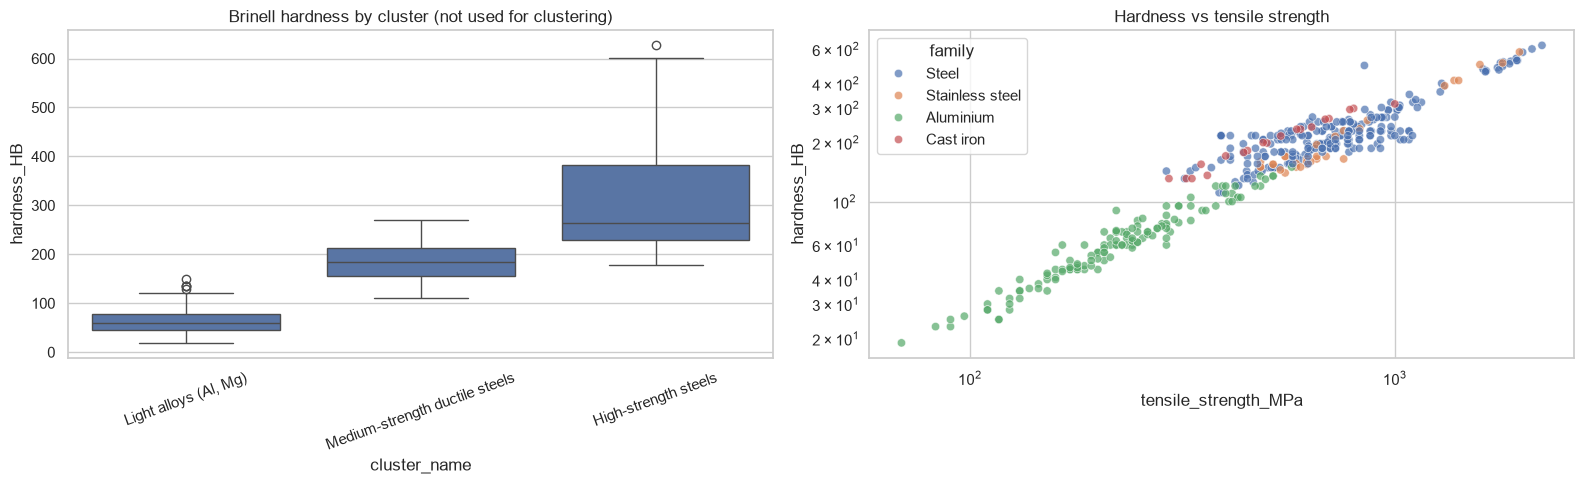

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = hb.groupby("cluster_name")["hardness_HB"].median().sort_values().index
sns.boxplot(data=hb, x="cluster_name", y="hardness_HB", order=order, ax=axes[0])
axes[0].set_title("Brinell hardness by cluster (not used for clustering)")
axes[0].tick_params(axis="x", rotation=20)
sns.scatterplot(data=hb, x="tensile_strength_MPa", y="hardness_HB", hue="family", alpha=0.7, ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_title("Hardness vs tensile strength")
plt.tight_layout(); plt.savefig("../figures/09_hardness_check.png", dpi=150); plt.show()

In [5]:
idx = hb.index
Xh = X.loc[idx].copy()
logHB = np.log10(hb["hardness_HB"])
Xh["hardness_HB"] = (logHB - logHB.mean()) / logHB.std(ddof=0)
final = meta.loc[idx, "cluster"].values

for k in (3, 4):
    base   = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(Xh.drop(columns="hardness_HB"))
    with_h = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(Xh)
    print(f"k={k}: ARI (5 features vs +hardness) = {adjusted_rand_score(base, with_h):.3f} | "
          f"ARI (final model vs +hardness) = {adjusted_rand_score(final, with_h):.3f} | "
          f"silhouette {silhouette_score(Xh.drop(columns='hardness_HB'), base):.3f} -> "
          f"{silhouette_score(Xh, with_h):.3f}")

k=3: ARI (5 features vs +hardness) = 0.993 | ARI (final model vs +hardness) = 0.937 | silhouette 0.470 -> 0.460
k=4: ARI (5 features vs +hardness) = 0.881 | ARI (final model vs +hardness) = 0.834 | silhouette 0.409 -> 0.393


## Hardness check
Among the 1,235 modelled materials, 513 report hardness (419 Brinell, 94 Vickers, never both) and 722 report none. Brinell hardness is available for 66% of aluminium, 46% of cast iron, 35% of steel, 27% of stainless steel and none of the copper or magnesium alloys. HB correlates strongly with tensile strength (Spearman 0.926, n = 419), and the median tensile/HB ratio for steels is 3.40, close to the commonly quoted rule of thumb (about 3.45), so the two properties are consistent. Median HB rises across the clusters (light alloys 60, medium-strength steels 185, high-strength steels 264), an independent confirmation that the clusters are strength tiers. Adding standardized log HB to the five features on this subset changes the clustering only modestly (ARI 0.88 at k=4) and does not improve silhouette, as expected because hardness is nearly a function of strength. Hardness was therefore left out of the main model.